# Core calibration & validation

Logs are indirect; **core is ground truth**. An interpretation is credible only if it reproduces
the core where core exists. Well **30/6-5** carries 200 core plugs over its reservoir, so we check
the library against them: total porosity vs core, permeability vs core, and then against
independent NPD ground truth across the North Sea. All library calls.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow

well = read_las(REPO / "petrophys" / "data" / "geolink" / "30_6-5.las")
run_dynamic_workflow(well, lithology="clastic")
g = lambda *n: next((np.asarray(well.get(x).data, float) for x in n if well.get(x) is not None), None)
phit, phic = g("PHIT"), g("PHIC")
m = np.isfinite(phic) & np.isfinite(phit)
print(f"{m.sum()} core plugs | PHIT vs core: bias {np.nanmean(phit[m]-phic[m]):+.3f}, "
      f"MAE {np.nanmean(np.abs(phit[m]-phic[m])):.3f}")

200 core plugs | PHIT vs core: bias +0.011, MAE 0.034


## Total porosity vs core

Routine core porosity (helium) is **total** pore volume, so the comparison is to computed
**PHIT**. They agree to ~1 porosity unit. Effective porosity (`PHIE`) sits below core by the
clay-bound water, which is the expected physical relationship.

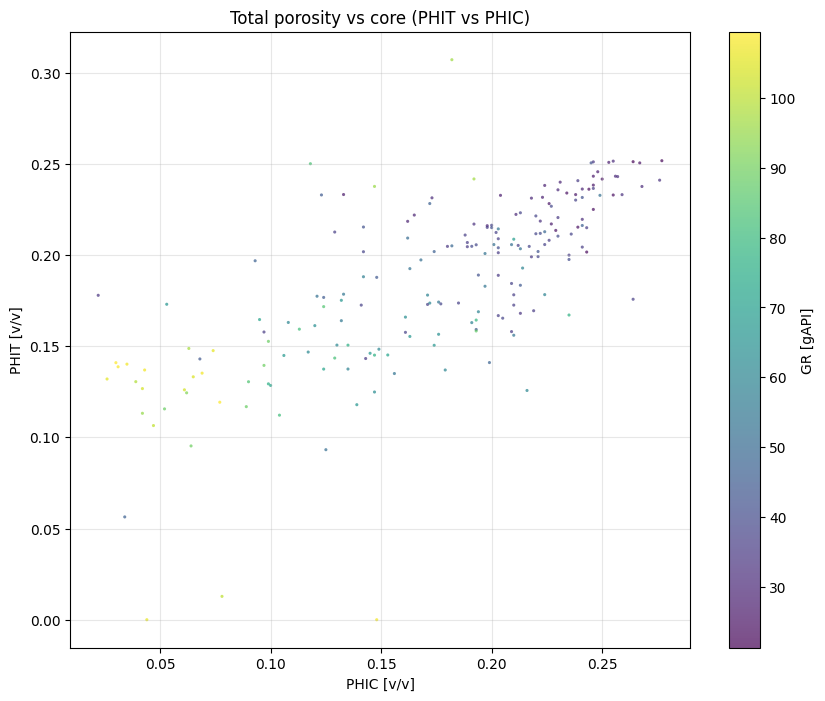

In [2]:
from petrophys.visualization import create_crossplot
create_crossplot(well, x_curve="PHIC", y_curve="PHIT", color_curve="GR",
                 title="Total porosity vs core (PHIT vs PHIC)");

## Permeability vs core

Permeability spans orders of magnitude (log axes). A core-calibrated transform (`PERM_CC`) tracks
the core plugs (`KH_CORE`) closely.

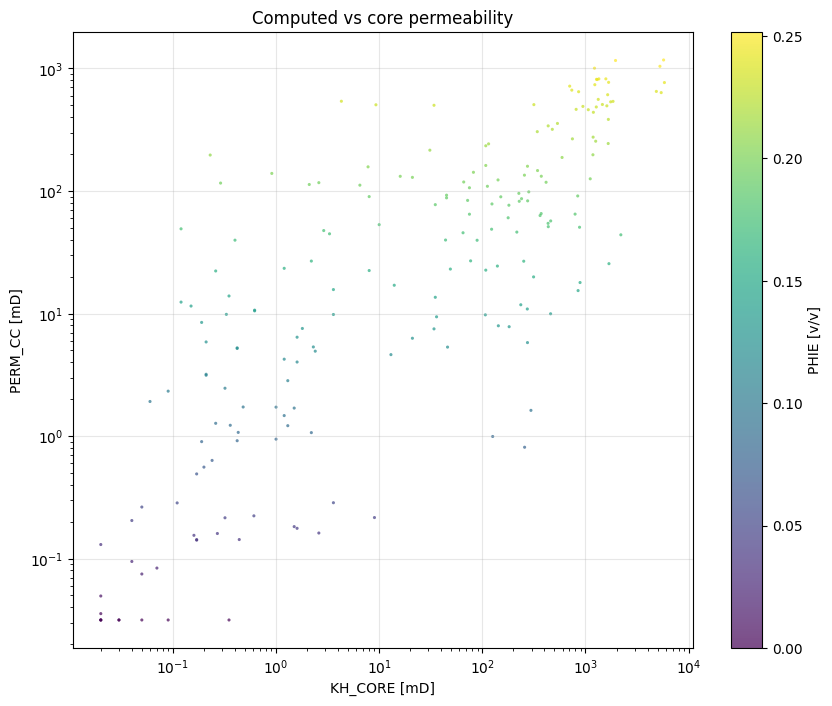

In [3]:
create_crossplot(well, x_curve="KH_CORE", y_curve="PERM_CC", color_curve="PHIE",
                 x_log=True, y_log=True, title="Computed vs core permeability");

## Independent validation: NPD ground truth

One well's core is necessary but not sufficient. The library's net-pay is also checked against
**Norwegian Petroleum Directorate** wellbore reports: public, independent ground truth on which
wells are dry and which produce. Across the North Sea set (run
`scripts/validate_porosity_saturation.py` with the full data via `PETROPHYS_GEOLINK_DIR`):

| well group | computed net pay | NPD outcome |
|---|---|---|
| **30/6-5** (cored) | 30 m; total porosity 0.197 vs core 0.193 | discovery, core-matched |
| **NPD-dry wells** (median) | ~11 m | dry, reads as water |
| **gas wells** (median) | ~75 m | gas |

The agreement rests on three modelling choices, each visible in the workflow decision log:
**neutron-density-primary clay** (sensitive to non-radioactive clay), **bad-hole exclusion**
(washed-out intervals, where porosity and Sw are unreliable, are kept out of net pay), and an
**Rwa-distribution Rw** (median where the section is all-wet, low tail where a hydrocarbon leg is
present).

In [4]:
net_pay_m = np.nansum(g("NET_PAY") > 0.5) * (well.step or 0.15)
print(f"30/6-5: net pay {net_pay_m:.1f} m | total porosity {np.nanmedian(phit[m]):.3f} "
      f"vs core {np.nanmedian(phic[m]):.3f}")

30/6-5: net pay 30.2 m | total porosity 0.197 vs core 0.193


**Takeaways**

* Computed **total porosity reproduces core** to ≈ 1 p.u.; permeability tied to core beats a
  log-only estimate.
* The library's **net-pay agrees with independent NPD ground truth**: dry wells read as water,
  gas wells show pay, alongside the core match.
* Reproducible from the bundled well; the multi-well harness is `scripts/validate_porosity_saturation.py`.